### Filter-Based Feature Selection and Weight of Evidence Ranking
This notebook implements a transparent, sequential filter methodology to reduce the 75 candidate variables down to the final most predictive, independent risk drivers for the Challenger PPGD model.

In [ ]:
import os
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import roc_auc_score

plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.dpi'] = 110

# Load Training Cohort
data_path = "../data/synthetic_portfolio/train_portfolio_2019_2024.csv"
df = pd.read_csv(data_path, keep_default_na=False, na_values=[""])

target = "possession_flag"
id_cols = ["account_id", "default_date", "default_quarter", "default_year"]
candidate_features = [c for c in df.columns if c not in id_cols + [target]]

# Ensure numeric columns with missing values are properly typed as float
for col in candidate_features:
    if col in ["legacy_affordability_score", "secondary_employer_tenure_m"]:
        df[col] = pd.to_numeric(df[col], errors="coerce")

cat_features = df[candidate_features].select_dtypes(include=["object", "category"]).columns.tolist()
num_features = df[candidate_features].select_dtypes(exclude=["object", "category"]).columns.tolist()

print(f"Initial Candidate Features: {len(candidate_features)} ({len(num_features)} Numerical | {len(cat_features)} Categorical)")

Initial Candidate Features: 75 (49 Numerical | 26 Categorical)


### Validity & Completeness
1. **Validity:** Remove constant/zero-variance attributes that carry zero information.
2. **Completeness:** Remove attributes exceeding the 5% missing data threshold where imputation would introduce undue bias.

In [21]:
# Validity Filter
valid_features = []
dropped_validity = []

for col in candidate_features:
    if df[col].nunique(dropna=True) <= 1:
        dropped_validity.append(col)
    else:
        valid_features.append(col)

print(f"[Validity] Dropped {len(dropped_validity)} features: {dropped_validity}")
print(f"Remaining features: {len(valid_features)}\n")

# Completeness Filter (>5% missing)
complete_features = []
dropped_completeness = {}

for col in valid_features:
    miss_rate = df[col].isnull().mean()
    if miss_rate > 0.05:
        dropped_completeness[col] = f"{miss_rate*100:.2f}%"
    else:
        complete_features.append(col)

print(f"[Completeness] Dropped {len(dropped_completeness)} features (>5% missing): {dropped_completeness}")
print(f"Remaining features: {len(complete_features)}")

[Validity] Dropped 2 features: ['currency_denomination', 'legacy_system_constant_id']
Remaining features: 73

[Completeness] Dropped 2 features (>5% missing): {'legacy_affordability_score': '14.17%', 'secondary_employer_tenure_m': '21.83%'}
Remaining features: 71


### Categorical Concentration & Numerical Outlier Triming
1. **Concentration Filter:** Any categorical variable where a single category accounts for $>95\%$ of volume (or where non-dominant categories represent $<5\%$) is dropped due to severe class imbalance and unstable risk calibration.
2. **Outlier Treatment:** Numerical variables are clipped at the 1st and 99th percentiles to prevent extreme tail values from distorting binning and gradient steps.

In [22]:
# Categorical Concentration Filter
unconcentrated_features = []
dropped_concentration = {}

for col in complete_features:
    if col in cat_features:
        freq = df[col].value_counts(normalize=True, dropna=True)
        # Drop if dominant class > 95% (meaning remaining classes combined < 5%)
        if freq.iloc[0] > 0.95:
            dropped_concentration[col] = f"Top class '{freq.index[0]}' = {freq.iloc[0]*100:.2f}%"
        else:
            unconcentrated_features.append(col)
    else:
        unconcentrated_features.append(col)

print(f"[Concentration] Dropped {len(dropped_concentration)} biased categorical features:")
for k, v in dropped_concentration.items():
    print(f"  - {k}: {v}")
print(f"Remaining features: {len(unconcentrated_features)}\n")

#Numerical Outlier Winsorization (1% and 99% Trimmed Bounds)
df_clean = df[unconcentrated_features + [target]].copy()
winsor_bounds = {}

for col in unconcentrated_features:
    if col in num_features:
        p01, p99 = df_clean[col].quantile([0.01, 0.99])
        winsor_bounds[col] = (float(p01), float(p99))
        df_clean[col] = df_clean[col].clip(lower=p01, upper=p99)

print(f"[Outlier Treatment] Applied 1%/99% Winsorization to {len(winsor_bounds)} numerical features.")

[Concentration] Dropped 3 biased categorical features:
  - shared_ownership_scheme: Top class 'Standard_100_Pct' = 97.60%
  - Guarantor_Backed_Flag: Top class 'No_Guarantor' = 96.78%
  - staff_mortgage_indicator: Top class 'Non_Staff' = 98.86%
Remaining features: 68

[Outlier Treatment] Applied 1%/99% Winsorization to 46 numerical features.


### Weight of Evidence (WoE) Transformation & Univariate Ranking (gAUC)
Every surviving feature is transformed into its **Weight of Evidence (WoE)** representation:
$$\text{WoE}_i = \ln \left( \frac{\% \text{Non-Events}_i}{\% \text{Events}_i} \right)$$
We then compute the Univariate Group-Weighted ROC AUC (gAUC) and Information Value (IV) on each WoE-transformed variable to rank standalone discriminatory power transparently.

In [23]:
def compute_woe_and_gauc(series, y, is_cat=False, n_bins=10):
    temp = pd.DataFrame({"x": series, "y": y})
    if not is_cat and temp["x"].nunique() > n_bins:
        temp["bin"] = pd.qcut(temp["x"], q=n_bins, duplicates="drop").astype(str)
    else:
        temp["bin"] = temp["x"].astype(str)
        
    stats = temp.groupby("bin", observed=True)["y"].agg(["count", "sum"])
    stats["non_event"] = stats["count"] - stats["sum"]
    
    # Laplace-smoothed distributions to prevent log(0)
    dist_event = np.maximum(stats["sum"] / stats["sum"].sum(), 1e-6)
    dist_non_event = np.maximum(stats["non_event"] / stats["non_event"].sum(), 1e-6)
    
    stats["woe"] = np.log(dist_event / dist_non_event)
    stats["iv"] = (dist_event - dist_non_event) * stats["woe"]
    
    woe_feature = temp["bin"].map(stats["woe"]).astype(float)
    auc = roc_auc_score(y, woe_feature)
    gauc = max(auc, 1.0 - auc)
    total_iv = stats["iv"].sum()
    
    return woe_feature, gauc, total_iv

woe_df = pd.DataFrame(index=df_clean.index)
ranking_records = []

for col in unconcentrated_features:
    is_cat = col in cat_features
    woe_col, gauc, iv = compute_woe_and_gauc(df_clean[col], df_clean[target], is_cat=is_cat)
    woe_df[f"WoE_{col}"] = woe_col
    ranking_records.append({
        "Feature": col,
        "Type": "Categorical" if is_cat else "Numerical",
        "gAUC": round(gauc, 4),
        "IV": round(iv, 4)
    })

ranking_df = pd.DataFrame(ranking_records).sort_values(by="gAUC", ascending=False).reset_index(drop=True)
print("Top 20 Candidate Features Ranked by Univariate WoE gAUC:")
display(ranking_df.head(20))

Top 20 Candidate Features Ranked by Univariate WoE gAUC:


,Feature,Type,gAUC,IV
0,arrears_balance,Numerical,0.7044,0.5671
1,arrears_to_balance_ratio,Numerical,0.6868,0.4796
2,months_in_arrears,Numerical,0.6825,0.4999
3,days_past_due,Numerical,0.6778,0.4574
4,months_since_default,Numerical,0.6749,0.4480
5,missed_payments_12m,Numerical,0.6673,0.4001
6,current_ltv,Numerical,0.6568,0.3218
7,credit_score,Numerical,0.6435,0.2674
8,external_bureau_score,Numerical,0.6384,0.2476
9,broken_arrangements_12m,Numerical,0.6152,0.1802


### 6. Spearman Rank Correlation Filter on WoE Variables ($\vert{}\rho_s\vert{} > 0.70$)
To eliminate multicollinearity while preserving the strongest predictors, we compute the **Spearman Rank Correlation** across all `WoE_feature` columns in order of their gAUC rank. If a lower-ranked variable exhibits $\vert{}\rho_s\vert{} > 0.70$ with an already-accepted higher-ranked variable, it is dropped. Finally, the top 14 independent features are selected for model development.

[Spearman WoE Correlation] Dropped 12 collinear features (|rho| > 0.70):


,Dropped_Feature,Dropped_gAUC,Correlated_With_Kept,Spearman_Corr
0,arrears_to_balance_ratio,0.6868,arrears_balance,0.7759
1,days_past_due,0.6778,months_in_arrears,0.9869
2,months_since_default,0.6749,months_in_arrears,0.8501
3,missed_payments_12m,0.6673,months_in_arrears,0.8934
4,external_bureau_score,0.6384,credit_score,0.9585
5,original_ltv,0.6133,current_ltv,0.7241
6,cpi_inflation_rate,0.6008,boe_base_rate,0.8950
7,current_balance,0.5926,monthly_instalment_gbp,0.7978
8,regional_claimant_rate,0.5775,local_unemployment_rate,0.8963
9,original_balance,0.5762,monthly_instalment_gbp,0.7737



 FINAL 14 SELECTED CHALLENGER FEATURES:


,Feature,Type,gAUC,IV
1,arrears_balance,Numerical,0.7044,0.5671
2,months_in_arrears,Numerical,0.6825,0.4999
3,current_ltv,Numerical,0.6568,0.3218
4,credit_score,Numerical,0.6435,0.2674
5,broken_arrangements_12m,Numerical,0.6152,0.1802
6,monthly_instalment_gbp,Numerical,0.6094,0.1595
7,boe_base_rate,Numerical,0.6022,0.1362
8,local_unemployment_rate,Numerical,0.5815,0.0869
9,hpi_index_change_pct,Numerical,0.5766,0.0773
10,litigation_status,Categorical,0.5686,0.0966


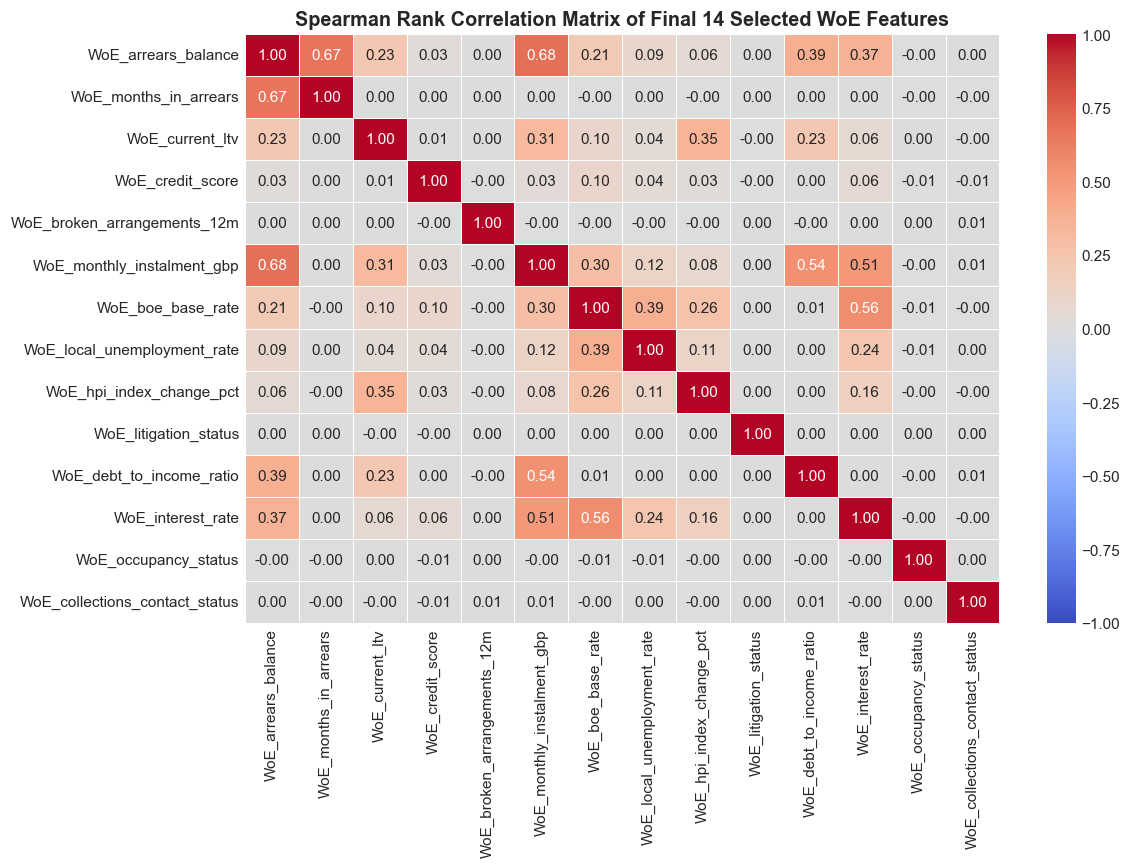

In [24]:
ordered_woe_cols = [f"WoE_{f}" for f in ranking_df["Feature"]]
spearman_matrix = woe_df[ordered_woe_cols].corr(method="spearman").abs()

accepted_features = []
dropped_correlated = []

for feat in ranking_df["Feature"]:
    woe_name = f"WoE_{feat}"
    if not accepted_features:
        accepted_features.append(feat)
        continue
        
    corr_conflict = None
    for kept in accepted_features:
        corr_val = spearman_matrix.loc[woe_name, f"WoE_{kept}"]
        if corr_val > 0.70: # type: ignore
            corr_conflict = (kept, corr_val)
            break
            
    if corr_conflict:
        dropped_correlated.append({
            "Dropped_Feature": feat,
            "Dropped_gAUC": ranking_df.loc[ranking_df["Feature"] == feat, "gAUC"].values[0],
            "Correlated_With_Kept": corr_conflict[0],
            "Spearman_Corr": round(corr_conflict[1], 4) #type: ignore
        })
    else:
        accepted_features.append(feat)

print(f"[Spearman WoE Correlation] Dropped {len(dropped_correlated)} collinear features (|rho| > 0.70):")
display(pd.DataFrame(dropped_correlated))

# Select Top 14 Final Challenger Features
FINAL_COUNT = 14
final_14_features = accepted_features[:FINAL_COUNT]
final_14_table = ranking_df[ranking_df["Feature"].isin(final_14_features)].copy().reset_index(drop=True)
final_14_table.index = final_14_table.index + 1

print(f"\n FINAL {FINAL_COUNT} SELECTED CHALLENGER FEATURES:")
display(final_14_table)

# Visualise Spearman Correlation Heatmap of the Final 14 WoE Features
plt.figure(figsize=(11, 8))
final_woe_cols = [f"WoE_{f}" for f in final_14_features]
sns.heatmap(
    woe_df[final_woe_cols].corr(method="spearman"),
    annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, linewidths=0.5
)
plt.title("Spearman Rank Correlation Matrix of Final 14 Selected WoE Features", fontsize=13, fontweight="bold")
plt.tight_layout()
plt.show()

In [25]:
# Final feature list
artefact_dir = "../data/model_artefacts"
os.makedirs(artefact_dir, exist_ok=True)

feature_metadata = {
    "final_14_features": final_14_features,
    "numerical_features": [f for f in final_14_features if f in num_features],
    "categorical_features": [f for f in final_14_features if f in cat_features],
    "winsor_bounds": {k: winsor_bounds[k] for k in final_14_features if k in winsor_bounds}
}

with open(f"{artefact_dir}/selected_features_metadata.json", "w") as f:
    json.dump(feature_metadata, f, indent=4)

print(f"Saved {len(final_14_features)} features ({len(feature_metadata['numerical_features'])} Num | {len(feature_metadata['categorical_features'])} Cat) to {artefact_dir}/selected_features_metadata.json")

Saved 14 features (11 Num | 3 Cat) to ../data/model_artefacts/selected_features_metadata.json
